In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [4]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('/content/Iris (1).csv')

# Menampilkan 5 data pertama
df.head()

Saving Iris (1).csv to Iris (1) (1).csv


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
# Melihat jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

# Melihat nama kolom
print("\nNama kolom:")
print(df.columns)

# Melihat informasi dataset
df.info()

# Memeriksa data kosong
print("\nData kosong:")
print(df.isnull().sum())

Ukuran dataset: (150, 6)

Nama kolom:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Data kosong:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [6]:
# Mengambil 100 sampel secara acak
data = df.sample(n=100, random_state=42)

# Mengambil variabel SepalLengthCm
x = data['SepalLengthCm'].values

# Menampilkan data
print(data[['SepalLengthCm']])

# Memeriksa jumlah sampel
print("\nJumlah sampel:", len(x))

     SepalLengthCm
73             6.1
18             5.7
118            7.7
78             6.0
76             6.8
..             ...
89             5.5
8              4.4
13             4.3
119            6.0
125            7.2

[100 rows x 1 columns]

Jumlah sampel: 100


In [7]:
n = len(x)

rata_rata = np.mean(x)
standar_deviasi = np.std(x, ddof=1)
varians = np.var(x, ddof=1)

print("Jumlah sampel:", n)
print("Rata-rata:", rata_rata)
print("Standar deviasi:", standar_deviasi)
print("Varians:", varians)

Jumlah sampel: 100
Rata-rata: 5.798000000000001
Standar deviasi: 0.8333915131205826
Varians: 0.6945414141414142


In [8]:
# Menghitung estimasi titik
estimasi_titik = np.mean(x)

print("Hasil Estimasi Titik:", estimasi_titik)

Hasil Estimasi Titik: 5.798000000000001


In [9]:
# Tingkat kesalahan 5%
alpha = 0.05

# Nilai Z
z = norm.ppf(1 - alpha/2)

# Menghitung standard error
standard_error = standar_deviasi / np.sqrt(n)

# Menghitung margin of error
margin_error = z * standard_error

# Batas bawah dan batas atas
batas_bawah = rata_rata - margin_error
batas_atas = rata_rata + margin_error

print("Nilai Z:", z)
print("Estimasi titik:", rata_rata)
print("Standard Error:", standard_error)
print("Margin of Error:", margin_error)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

print("\nEstimasi Interval 95%:")
print(f"({batas_bawah:.4f}, {batas_atas:.4f})")

Nilai Z: 1.959963984540054
Estimasi titik: 5.798000000000001
Standard Error: 0.08333915131205825
Margin of Error: 0.16334173507376817
Batas bawah: 5.634658264926233
Batas atas: 5.961341735073769

Estimasi Interval 95%:
(5.6347, 5.9613)


In [10]:
# Menampung hasil Jackknife
jackknife_results = []

# Proses Jackknife
for i in range(n):

    # Menghapus satu data secara bergantian
    sampel_jackknife = np.delete(x, i)

    # Menghitung rata-rata
    mean_jackknife = np.mean(sampel_jackknife)

    # Menyimpan hasil
    jackknife_results.append(mean_jackknife)

# Menghitung rata-rata hasil Jackknife
rata_jackknife = np.mean(jackknife_results)

print("Jumlah iterasi Jackknife:", len(jackknife_results))
print("Rata-rata hasil Jackknife:", rata_jackknife)

Jumlah iterasi Jackknife: 100
Rata-rata hasil Jackknife: 5.798000000000001


In [11]:
# Menentukan jumlah iterasi
B = 1000

# Menampung hasil Bootstrapping
bootstrap_results = []

# Proses Bootstrapping
np.random.seed(42)

for i in range(B):

    # Mengambil sampel dengan pengembalian
    sampel_bootstrap = np.random.choice(
        x,
        size=n,
        replace=True
    )

    # Menghitung rata-rata sampel
    mean_bootstrap = np.mean(sampel_bootstrap)

    # Menyimpan hasil
    bootstrap_results.append(mean_bootstrap)

# Menghitung rata-rata hasil Bootstrapping
rata_bootstrap = np.mean(bootstrap_results)

print("Jumlah iterasi Bootstrapping:", B)
print("Rata-rata hasil Bootstrapping:", rata_bootstrap)

Jumlah iterasi Bootstrapping: 1000
Rata-rata hasil Bootstrapping: 5.798018


In [12]:
# Standar error Jackknife
se_jackknife = np.sqrt(
    (n - 1) / n *
    np.sum((np.array(jackknife_results) -
            rata_jackknife)**2)
)

# Standar error Bootstrapping
se_bootstrap = np.std(bootstrap_results, ddof=1)

print("Standard Error Jackknife:", se_jackknife)
print("Standard Error Bootstrapping:", se_bootstrap)

Standard Error Jackknife: 0.08333915131205864
Standard Error Bootstrapping: 0.08091444137373029


In [13]:
hasil = pd.DataFrame({
    'Metode': [
        'Estimasi Titik',
        'Jackknife',
        'Bootstrapping'
    ],
    'Rata-rata': [
        rata_rata,
        rata_jackknife,
        rata_bootstrap
    ],
    'Standard Error': [
        standard_error,
        se_jackknife,
        se_bootstrap
    ]
})

print(hasil.to_string(index=False))

        Metode  Rata-rata  Standard Error
Estimasi Titik   5.798000        0.083339
     Jackknife   5.798000        0.083339
 Bootstrapping   5.798018        0.080914


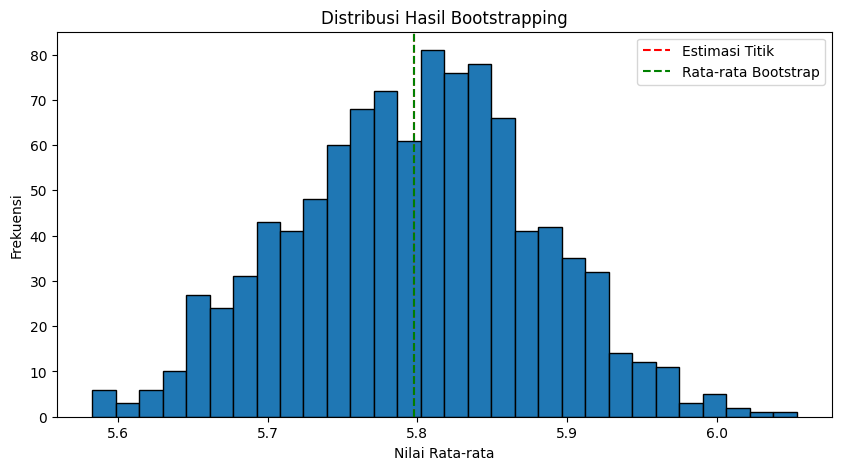

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(bootstrap_results, bins=30, edgecolor='black')

plt.axvline(
    rata_rata,
    color='red',
    linestyle='--',
    label='Estimasi Titik'
)

plt.axvline(
    rata_bootstrap,
    color='green',
    linestyle='--',
    label='Rata-rata Bootstrap'
)

plt.title('Distribusi Hasil Bootstrapping')
plt.xlabel('Nilai Rata-rata')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

In [16]:
# Menyimpan 100 sampel
data.to_csv('Data_100_Sampel.csv', index=False)

# Menyimpan tabel hasil perhitungan
hasil.to_csv('Hasil_Perhitungan.csv', index=False)

# Menyimpan hasil seluruh iterasi menggunakan pd.Series untuk mengatasi perbedaan panjang data
resampling = pd.DataFrame({
    'Jackknife': pd.Series(jackknife_results),
    'Bootstrapping': pd.Series(bootstrap_results)
})

resampling.to_csv('Hasil_Resampling.csv', index=False)

print("Semua file berhasil disimpan!")

Semua file berhasil disimpan!
